In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (2000, 10)

First 5 Rows:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB

Statistical Summary:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


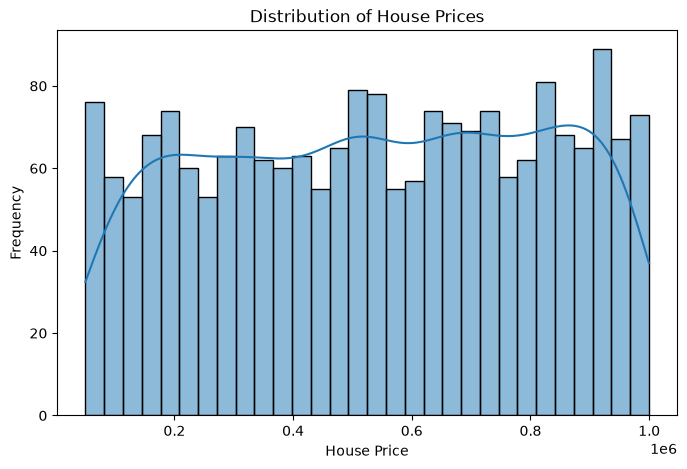

In [2]:
#House price distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Price"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.show()

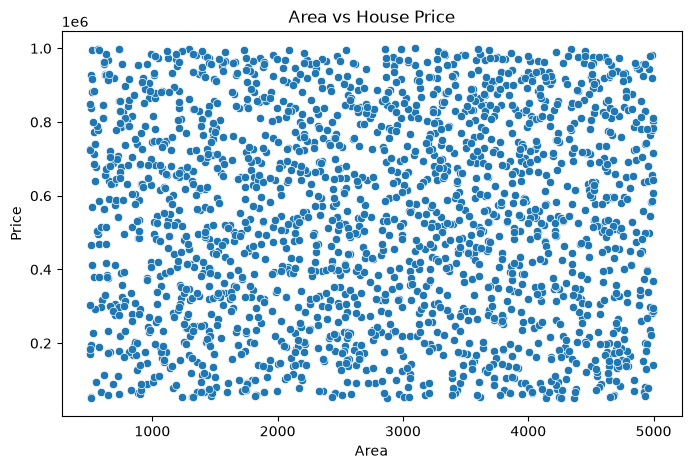

In [6]:
# Relationship between area and price
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Area", y="Price")

plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

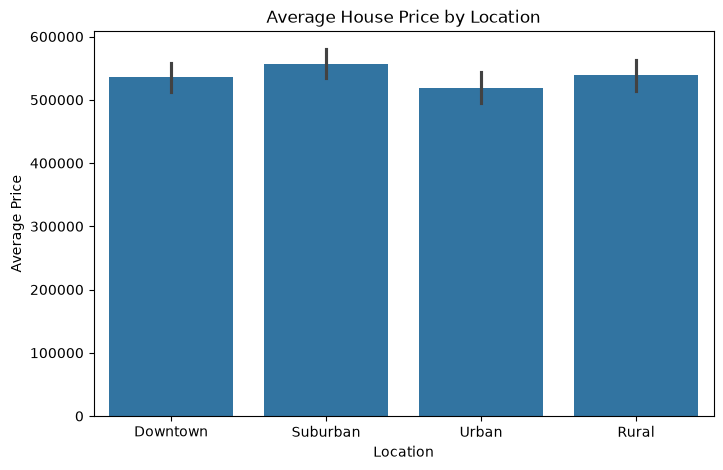

In [7]:
# Average price by location

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Location", y="Price")

plt.title("Average House Price by Location")
plt.xlabel("Location")
plt.ylabel("Average Price")
plt.show()

In [8]:
# Correlation Analysis.
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Remove Id because it is only an identifier
numeric_df = numeric_df.drop(columns=["Id"])

# Calculate correlation
correlation = numeric_df.corr()

# Display correlation with Price
print(correlation["Price"].sort_values(ascending=False))

Price        1.000000
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Name: Price, dtype: float64


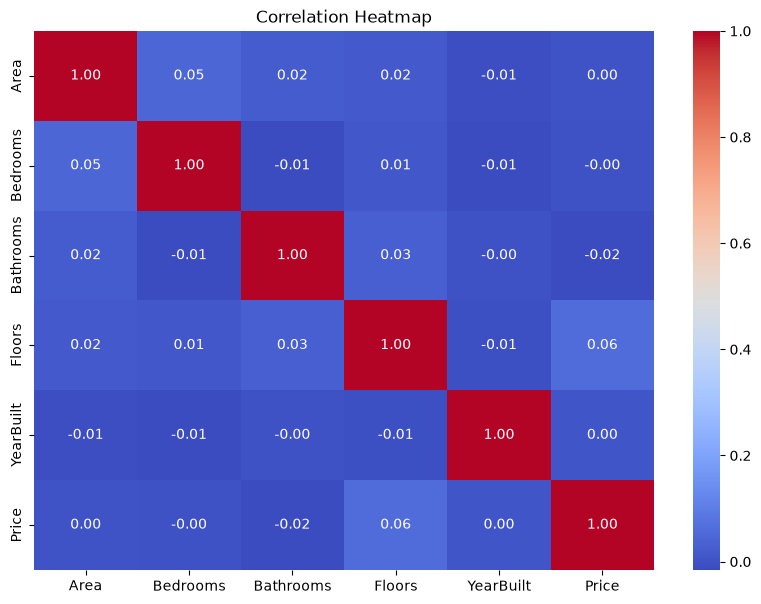

In [9]:
# Now visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [10]:
#check missing values 
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [11]:
#check duplicate records 
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [12]:
print("Location Values:")
print(df["Location"].value_counts())

print("\nCondition Values:")
print(df["Condition"].value_counts())

print("\nGarage Values:")
print(df["Garage"].value_counts())

Location Values:
Location
Downtown    558
Urban       485
Suburban    483
Rural       474
Name: count, dtype: int64

Condition Values:
Condition
Fair         521
Excellent    511
Poor         507
Good         461
Name: count, dtype: int64

Garage Values:
Garage
No     1038
Yes     962
Name: count, dtype: int64


In [13]:
# Check numerical ranges

print(df[["Area", "Bedrooms", "Bathrooms",
          "Floors", "YearBuilt", "Price"]].describe())

              Area     Bedrooms   Bathrooms       Floors    YearBuilt  \
count  2000.000000  2000.000000  2000.00000  2000.000000  2000.000000   
mean   2786.209500     3.003500     2.55250     1.993500  1961.446000   
std    1295.146799     1.424606     1.10899     0.809188    35.926695   
min     501.000000     1.000000     1.00000     1.000000  1900.000000   
25%    1653.000000     2.000000     2.00000     1.000000  1930.000000   
50%    2833.000000     3.000000     3.00000     2.000000  1961.000000   
75%    3887.500000     4.000000     4.00000     3.000000  1993.000000   
max    4999.000000     5.000000     4.00000     3.000000  2023.000000   

               Price  
count    2000.000000  
mean   537676.855000  
std    276428.845719  
min     50005.000000  
25%    300098.000000  
50%    539254.000000  
75%    780086.000000  
max    999656.000000  


In [19]:
# separate features and target
# Remove Id because it is only an identifier
X = df.drop(columns=["Id", "Price"])

# Target variable
y = df["Price"]

In [20]:
X_encoded = pd.get_dummies(
    X,
    columns=["Location", "Condition", "Garage"],
    drop_first=True,
    dtype=int
)

In [21]:
# check encoding 
print("Original Features:", X.shape)

print("Encoded Features:", X_encoded.shape)

display(X_encoded.head())

Original Features: (2000, 8)
Encoded Features: (2000, 12)


,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,1970,0,0,0,0,0,0,0
1,4272,5,4,3,1958,0,0,0,0,0,0,0
2,3592,2,2,3,1938,0,0,0,0,1,0,0
3,966,4,2,2,1902,0,1,0,1,0,0,1
4,4926,1,4,2,1975,0,0,0,1,0,0,1


In [22]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (1600, 12)
Testing Features: (400, 12)
Training Target: (1600,)
Testing Target: (400,)


In [23]:
# linear regression model trining 
from sklearn.linear_model import LinearRegression

In [25]:
model = LinearRegression()

In [26]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ -0.58, 76.78, -9662.25,...,-12941.04, 4073.27, 2373.53]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['Area','Bedrooms','Bathrooms',...,'Condition_Good','Condition_Poor', 'Garage_Yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.785e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [27]:
# Check model coefficients
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

display(coefficients)

Intercept: 278520.5311222263


,Feature,Coefficient
0,Area,-0.575754
1,Bedrooms,76.784827
2,Bathrooms,-9662.248234
3,Floors,23727.983633
4,YearBuilt,117.613885
5,Location_Rural,1317.542020
6,Location_Suburban,11511.989815
7,Location_Urban,-12718.918912
8,Condition_Fair,24083.307846
9,Condition_Good,-12941.044835


In [28]:
# Model Prediction and Performance Evaluation.
y_pred = model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred[:10])

First 10 Actual Prices:
[514764 694256  66375 650243 223285 468127 513002 911525 723265 339416]

First 10 Predicted Prices:
[521988.22189839 549119.31196651 487101.22235594 539752.7439933
 553242.24872512 521375.92025826 523320.18080583 578133.64353335
 545899.64738458 577368.69940644]


In [29]:
# compare actual vs predict price 
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

display(comparison.head(10))

,Actual Price,Predicted Price,Difference
0,514764,521988.221898,-7224.221898
1,694256,549119.311967,145136.688033
2,66375,487101.222356,-420726.222356
3,650243,539752.743993,110490.256007
4,223285,553242.248725,-329957.248725
5,468127,521375.920258,-53248.920258
6,513002,523320.180806,-10318.180806
7,911525,578133.643533,333391.356467
8,723265,545899.647385,177365.352615
9,339416,577368.699406,-237952.699406


In [30]:
# evaluate model performance 
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 243241.97758826384
Mean Squared Error: 78321466146.0328
Root Mean Squared Error: 279859.72583784326
R2 Score: -0.006717808430749761


In [32]:
# Residual Analysis
residuals = y_test - y_pred

print("First 10 Residuals:")
print(residuals.head(10))


First 10 Residuals:
1860     -7224.221898
353     145136.688033
1333   -420726.222356
905     110490.256007
1289   -329957.248725
1273    -53248.920258
938     -10318.180806
1731    333391.356467
65      177365.352615
1323   -237952.699406
Name: Price, dtype: float64


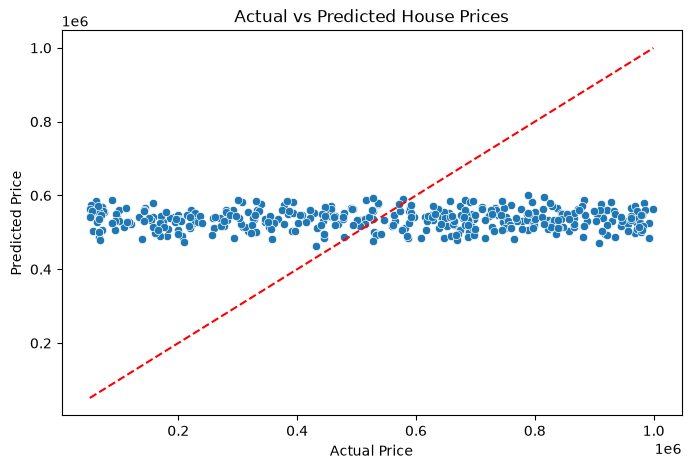

In [33]:
# actual vs predic plot
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

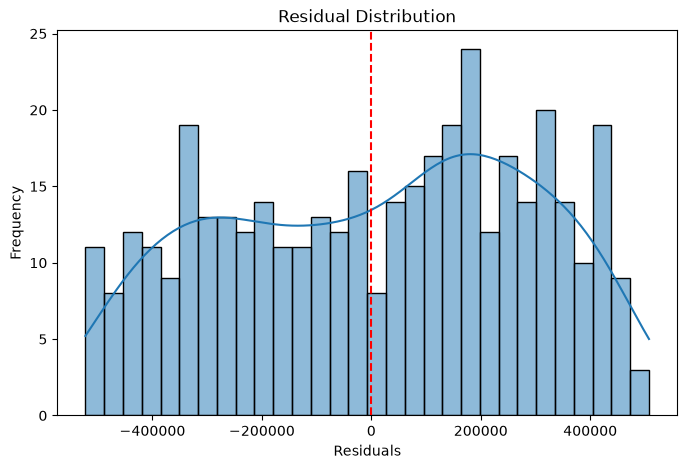

In [34]:
# resuduall distribution 
plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()

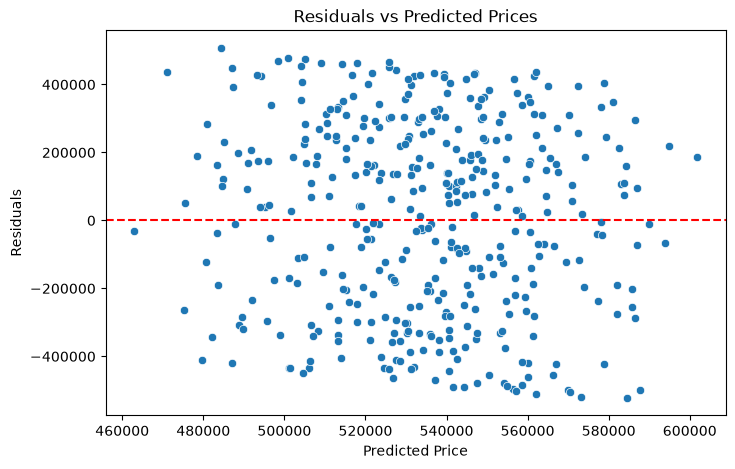

In [35]:
# resudual vs predicted plot
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Prices")
plt.show()

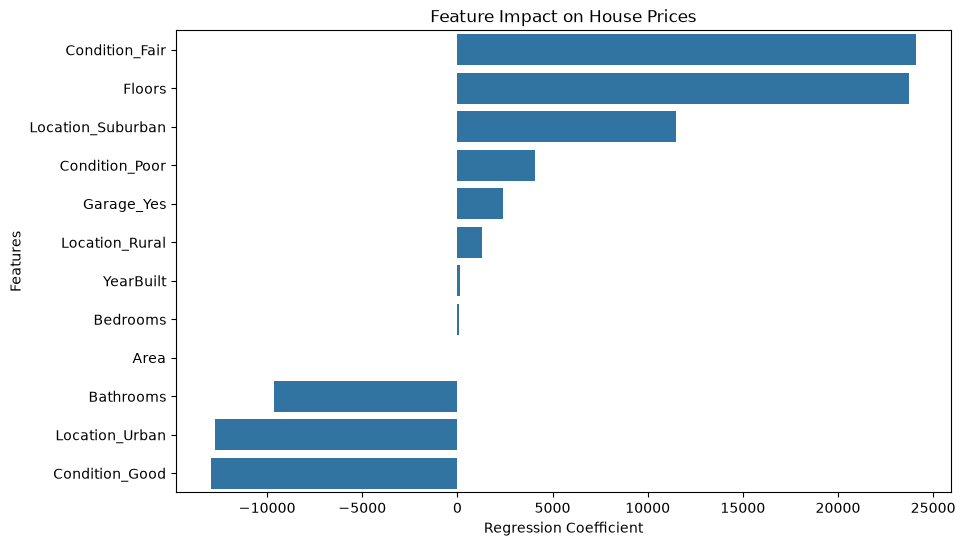

In [36]:
# display future coefficients 
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Feature Impact on House Prices")
plt.xlabel("Regression Coefficient")
plt.ylabel("Features")
plt.show()

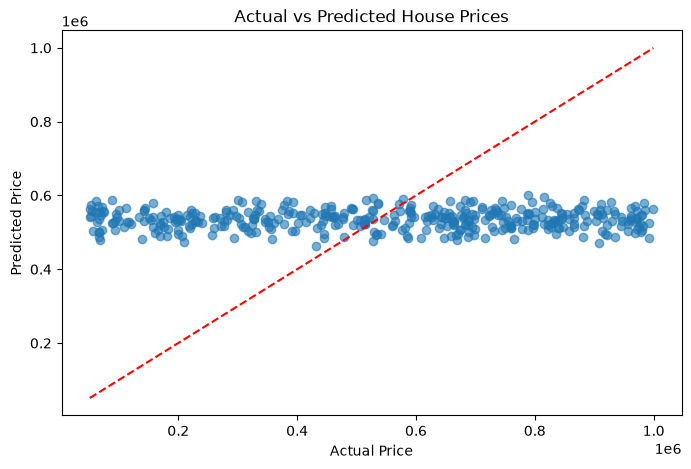

In [37]:
# actual vs predicted price 
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

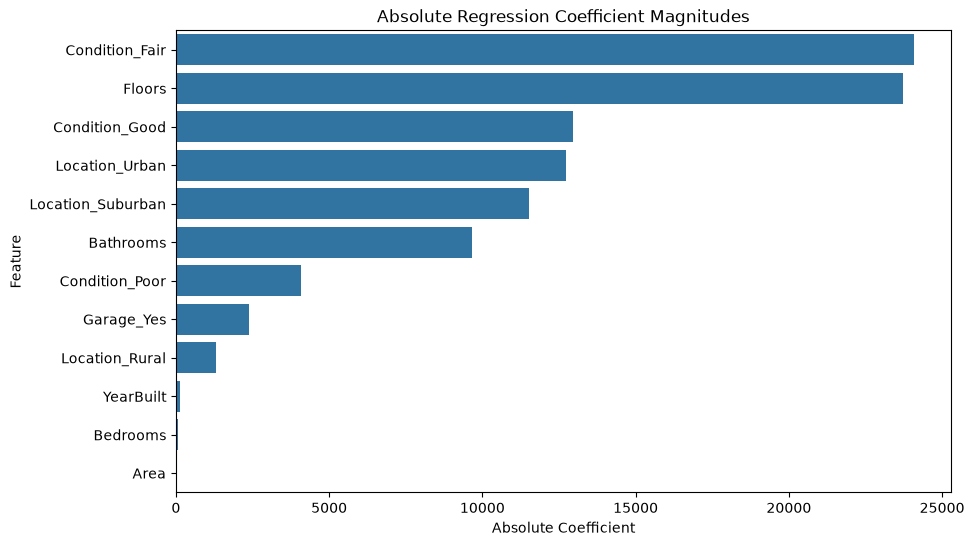

In [38]:
# future importance in  visualization 
feature_impact = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

feature_impact["Absolute Impact"] = (
    feature_impact["Coefficient"].abs()
)

feature_impact = feature_impact.sort_values(
    "Absolute Impact",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_impact,
    x="Absolute Impact",
    y="Feature"
)

plt.title("Absolute Regression Coefficient Magnitudes")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Feature")
plt.show()

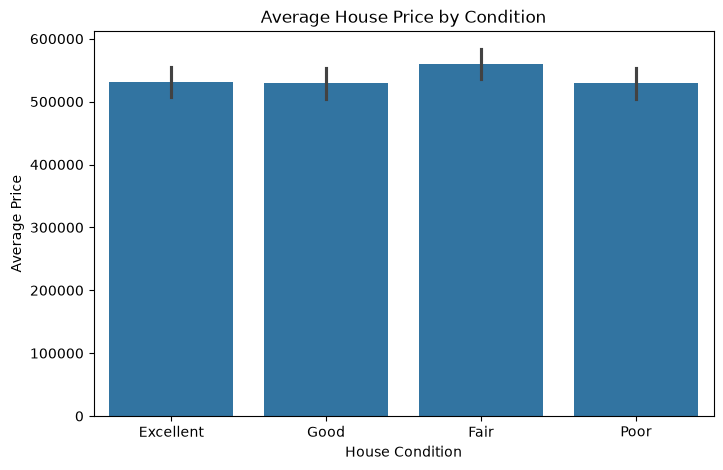

In [39]:
# Average House Price by Condition

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Condition", y="Price")

plt.title("Average House Price by Condition")
plt.xlabel("House Condition")
plt.ylabel("Average Price")
plt.show()

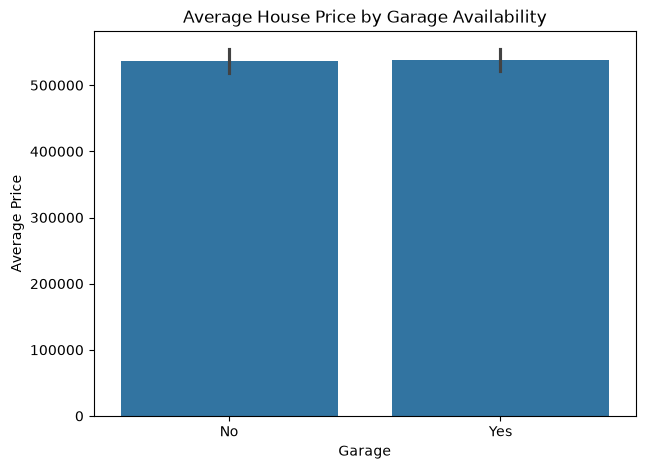

In [40]:
# Average House Price by Garage Availability
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="Garage", y="Price")

plt.title("Average House Price by Garage Availability")
plt.xlabel("Garage")
plt.ylabel("Average Price")
plt.show()

In [41]:
# Final model performance summary
print("HOUSE PRICE PREDICTION - MODEL SUMMARY")
print("--------------------------------------")
print("Algorithm: Linear Regression")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

HOUSE PRICE PREDICTION - MODEL SUMMARY
--------------------------------------
Algorithm: Linear Regression
Training records: 1600
Testing records: 400
MAE: 243241.98
RMSE: 279859.73
R2 Score: -0.0067
